# LQD: Lagged Short-Term Momentum

Go long when LQD breaks above its recent highs and short when it breaks below its recent lows, betting the move continues.

The first version used three higher highs in a row. That turned out to be noise (see below), so we test new highs and lows over windows of 5 to 60 days instead.

**Rules**
- New high: today's high is above every high of the previous $W$ days. New low: today's low is below every low of the previous $W$ days.
- After a new high, go long. After a new low, go short (long/short) or to cash (long/flat).
- Hold for $H$ days after the last signal, or until the opposite signal.
- Signals use day $t$'s prices and are traded for day $t+1$.
- Cost: 1 bp per 100% of capital traded.

**Parameters**
- $W \in \{5, 10, 15, 20, 30, 40, 60\}$, $H \in \{1, 2, 3, 5, 10, 20, \text{until opposite}\}$, long/short and long/flat.
- Pick the highest Sharpe on 2004-2017, then test once on 2018-2026.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

In [2]:
DATA_FILE = 'data/LQD_ohlc.csv'
START, END = '2002-12-31', '2026-11-19'   # end date is exclusive, so the data is fixed

TRAIN = ('2004-01-01', '2017-12-31')
TEST = ('2018-01-01', None)
FULL = ('2004-01-01', None)

COST_BPS = 1.0
WINDOWS = [5, 10, 15, 20, 30, 40, 60]
HOLDS = [1, 2, 3, 5, 10, 20, None]   # None = until the opposite signal

## Data

Daily adjusted prices for LQD from Yahoo Finance (includes distributions), saved to `data/`.

In [3]:
if os.path.exists(DATA_FILE):
    ohlc = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)
else:
    import yfinance as yf
    ohlc = yf.download('LQD', start=START, end=END, auto_adjust=True, progress=False)
    ohlc.columns = ohlc.columns.get_level_values(0)
    ohlc = ohlc[['Open', 'High', 'Low', 'Close']].dropna()
    ohlc.to_csv(DATA_FILE)

returns = ohlc['Close'].pct_change().fillna(0)
print(f'{len(ohlc):,} days, {ohlc.index[0].date()} to {ohlc.index[-1].date()}')
ohlc.tail()

6,010 days, 2002-12-31 to 2026-11-18


,Open,High,Low,Close
Date,,,,
2026-11-12,103.690002,103.800003,103.040001,103.050003
2026-11-13,102.870003,103.050003,102.739998,102.809998
2026-11-16,102.930000,103.099998,102.779999,102.800003
2026-11-17,102.650002,102.949997,102.610001,102.739998
2026-11-18,102.970001,103.209999,102.900002,103.150002


## Does LQD keep going?

Training years only: what happens after 3 higher highs in a row, and after a new $W$-day high or low.

In [4]:
train = slice(*TRAIN)
close = ohlc['Close'].loc[:TRAIN[1]]                 # cut at the end of training so 2018 never leaks in
next_day = close.pct_change().shift(-1)[train]
next_20 = (close.shift(-20) / close - 1)[train]

print('Autocorrelation of daily returns (2004-2017):',
      ', '.join(f'lag {k}: {returns[train].autocorr(k):+.3f}' for k in [1, 2, 5]))
print(f'Average next day: {next_day.mean() * 1e4:.2f} bp, average next 20 days: {next_20.mean():.2%}')

higher_high = (ohlc['High'] > ohlc['High'].shift(1)).astype(int)
lower_low = (ohlc['Low'] < ohlc['Low'].shift(1)).astype(int)
up3 = (higher_high.rolling(3).sum() == 3)[train]
down3 = (lower_low.rolling(3).sum() == 3)[train]
print(f'After 3 higher highs in a row: next day {next_day[up3].mean() * 1e4:.2f} bp ({up3.sum()} days)')
print(f'After 3 lower lows in a row:   next day {next_day[down3].mean() * 1e4:.2f} bp ({down3.sum()} days)\n')

rows = {}
for w in WINDOWS:
    new_high = (ohlc['High'] > ohlc['High'].shift(1).rolling(w).max())[train]
    new_low = (ohlc['Low'] < ohlc['Low'].shift(1).rolling(w).min())[train]
    rows[w] = {('after new high', 'days'): new_high.sum(),
               ('after new high', 'next day (bp)'): next_day[new_high].mean() * 1e4,
               ('after new high', 'next 20 days'): next_20[new_high].mean(),
               ('after new low', 'days'): new_low.sum(),
               ('after new low', 'next day (bp)'): next_day[new_low].mean() * 1e4,
               ('after new low', 'next 20 days'): next_20[new_low].mean()}
check = pd.DataFrame(rows).T
check.index.name = 'window W'
check.style.format('{:.0f}', subset=[c for c in check.columns if c[1] == 'days']) \
           .format('{:.2f}', subset=[c for c in check.columns if c[1] == 'next day (bp)']) \
           .format('{:.2%}', subset=[c for c in check.columns if c[1] == 'next 20 days'])

Autocorrelation of daily returns (2004-2017): lag 1: -0.091, lag 2: -0.098, lag 5: +0.004
Average next day: 2.14 bp, average next 20 days: 0.41%
After 3 higher highs in a row: next day 0.95 bp (588 days)
After 3 lower lows in a row:   next day -1.97 bp (341 days)



- After 3 higher highs in a row, the next day is below average. Daily returns slightly reverse (autocorrelation −0.09), so short streaks are noise.
- After a new high, the next 20 days are about average. After a new low, they are below average but still positive, so moving to cash should work better than shorting.

## Signal and back-test

In [5]:
def to_position(up, down, hold, short):
    '''Turn entry days into a position: 1 long, -1 short, 0 cash.'''
    entry = pd.Series(np.nan, index=ohlc.index)
    entry[up & ~down] = 1
    entry[down & ~up] = -1 if short else 0
    if hold is None:
        position = entry.ffill()
    elif hold == 1:
        position = entry
    else:
        position = entry.ffill(limit=hold - 1)
    return position.fillna(0)


def breakout_signal(window, hold=None, short=True):
    '''Long after a new `window`-day high, short (or cash) after a new `window`-day low.'''
    new_high = ohlc['High'] > ohlc['High'].shift(1).rolling(window).max()
    new_low = ohlc['Low'] < ohlc['Low'].shift(1).rolling(window).min()
    return to_position(new_high, new_low, hold, short)


def streak_signal(n, hold=None, short=True):
    '''Long after n higher highs in a row, short (or cash) after n lower lows in a row.'''
    return to_position(higher_high.rolling(n).sum() == n, lower_low.rolling(n).sum() == n, hold, short)


def backtest(signal, cost_bps=COST_BPS):
    '''Hold yesterday's signal today and pay costs on every change in position.'''
    held = signal.shift(1).fillna(0)
    traded = held.diff().abs().fillna(held.abs())
    return pd.DataFrame({'held': held, 'ret': held * returns - traded * cost_bps / 1e4})


def stats(bt, period):
    '''Performance statistics for one back-test over (start, end).'''
    r = bt.loc[slice(*period), 'ret']
    held = bt.loc[slice(*period), 'held']
    years = len(r) / 252
    equity = (1 + r).cumprod()
    return {
        'daily mean': r.mean(),
        'daily std': r.std(),
        'annual mean': r.mean() * 252,
        'annual std': r.std() * np.sqrt(252),
        'CAGR': equity.iloc[-1] ** (1 / years) - 1,
        'cumulative return': equity.iloc[-1] - 1,
        'max drawdown': (equity / equity.cummax().clip(lower=1) - 1).min(),
        'Sharpe': r.mean() / r.std() * np.sqrt(252),
        'time long': (held > 0).mean(),
        'time short': (held < 0).mean(),
        'trades per year': (held.diff().fillna(0) != 0).sum() / years,
    }


buy_hold = backtest(pd.Series(1.0, index=ohlc.index), cost_bps=0)

## Grid search

Picks use training data only. Test numbers are shown for comparison.

In [6]:
def hold_name(hold):
    return 'opp' if hold is None else str(hold)


rows = []
for short in [True, False]:
    for w in WINDOWS:
        for hold in HOLDS:
            bt = backtest(breakout_signal(w, hold, short))
            train_stats, test_stats = stats(bt, TRAIN), stats(bt, TEST)
            rows.append({'version': 'long/short' if short else 'long/flat', 'W': w, 'H': hold_name(hold),
                         'train Sharpe': train_stats['Sharpe'], 'test Sharpe': test_stats['Sharpe'],
                         'trades per year': train_stats['trades per year']})
grid = pd.DataFrame(rows)

picks = grid.loc[grid.groupby('version')['train Sharpe'].idxmax()].set_index('version')
print(f"Buy and hold Sharpe: train {stats(buy_hold, TRAIN)['Sharpe']:.2f}, test {stats(buy_hold, TEST)['Sharpe']:.2f}")
picks.round(2)

Buy and hold Sharpe: train 0.68, test 0.24


,W,H,train Sharpe,test Sharpe,trades per year
version,,,,,
long/flat,10,20,0.93,0.61,14.09
long/short,10,20,0.40,0.50,14.09


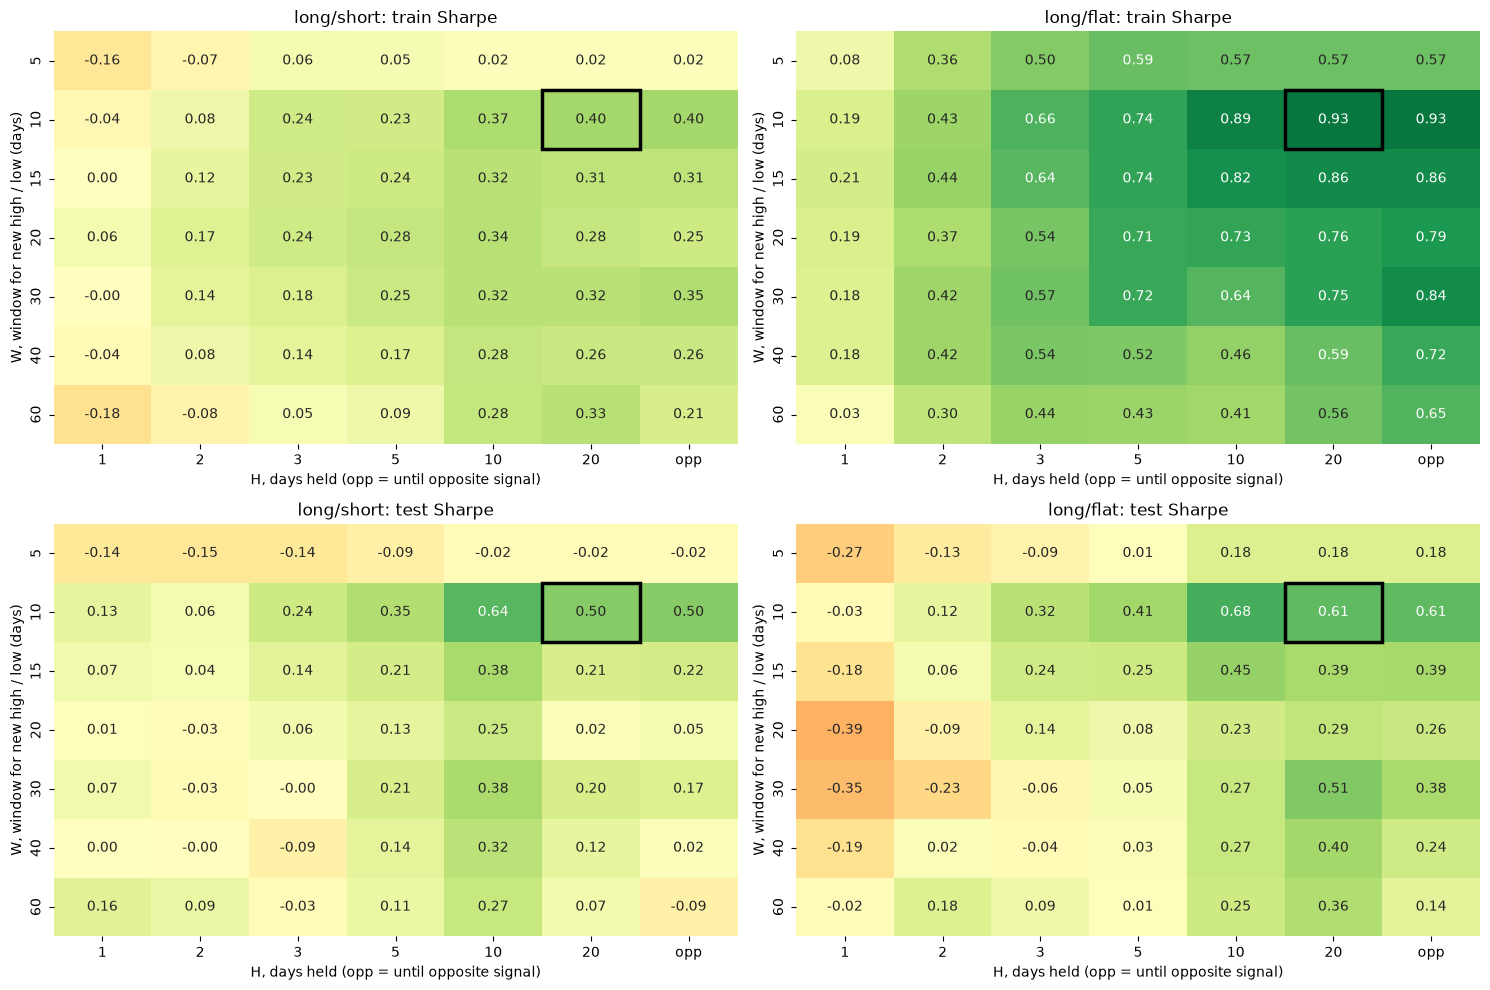

long/flat: train/test rank correlation 0.82, 18 of 49 rules beat buy and hold in the test period
long/short: train/test rank correlation 0.67, 10 of 49 rules beat buy and hold in the test period


In [7]:
H_ORDER = [hold_name(h) for h in HOLDS]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for row, column in enumerate(['train Sharpe', 'test Sharpe']):
    for col, version in enumerate(['long/short', 'long/flat']):
        table = grid[grid['version'] == version].pivot(index='W', columns='H', values=column)[H_ORDER]
        ax = axes[row, col]
        sns.heatmap(table, ax=ax, annot=True, fmt='.2f', cmap='RdYlGn', center=0, vmin=-1, vmax=1, cbar=False)
        pick = picks.loc[version]
        ax.add_patch(plt.Rectangle((H_ORDER.index(pick['H']), WINDOWS.index(pick['W'])), 1, 1,
                                   fill=False, edgecolor='black', lw=2.5))
        ax.set_title(f'{version}: {column}')
        ax.set_xlabel('H, days held (opp = until opposite signal)')
        ax.set_ylabel('W, window for new high / low (days)')
plt.tight_layout()
plt.show()

for version, g in grid.groupby('version'):
    rank_corr = g['train Sharpe'].rank().corr(g['test Sharpe'].rank())
    beat = (g['test Sharpe'] > stats(buy_hold, TEST)['Sharpe']).sum()
    print(f'{version}: train/test rank correlation {rank_corr:.2f}, {beat} of {len(g)} rules beat buy and hold in the test period')

- The good training results cover a broad region (W 10-30, H of 5 or more), not one lucky cell.
- Long/short never beats buy and hold in training, since a short position pays LQD's distributions.
- Both versions pick W = 10, H = 20. Training and test rankings agree well.

## Results

The test rows are the out-of-sample result.

In [8]:
signals = {'3-day streak, until opposite, long/short': streak_signal(3, None, short=True)}
for version, p in picks.iterrows():
    hold = None if p['H'] == 'opp' else int(p['H'])
    signals[f"Picked: W={p['W']}, H={p['H']}, {version}"] = breakout_signal(
        int(p['W']), hold, short=(version == 'long/short'))

strategies = {'Buy & hold': buy_hold, **{name: backtest(s) for name, s in signals.items()}}

results = pd.concat({
    name: pd.DataFrame({label: stats(bt, period) for label, bt in strategies.items()}).T
    for name, period in {'Train 2004-2017': TRAIN, 'Test 2018-2026': TEST, 'Full 2004-2026': FULL}.items()
})

os.makedirs('outputs', exist_ok=True)
results.to_csv('outputs/momentum_results.csv')
grid.to_csv('outputs/momentum_grid.csv', index=False)

percent = ['daily mean', 'daily std', 'annual mean', 'annual std', 'CAGR', 'cumulative return',
           'max drawdown', 'time long', 'time short']
results.style.format('{:.2%}', subset=percent).format('{:.3%}', subset=['daily mean', 'daily std']) \
       .format('{:.2f}', subset=['Sharpe', 'trades per year'])

### Trading costs

Test-period Sharpe at different costs.

In [9]:
pd.DataFrame({f'{c:g} bp': {name: stats(backtest(s, c), TEST)['Sharpe'] for name, s in signals.items()}
              for c in [0, 1, 5]}).round(2)

,0 bp,1 bp,5 bp
"3-day streak, until opposite, long/short",-0.27,-0.32,-0.49
"Picked: W=10, H=20, long/flat",0.64,0.61,0.51
"Picked: W=10, H=20, long/short",0.53,0.50,0.37


### Performance by period

2008-09 and 2022 were the big corporate bond sell-offs.

In [10]:
periods = {'2004-07': ('2004', '2007'), '2008-09': ('2008', '2009'), '2010-17': ('2010', '2017'),
           '2018-21': ('2018', '2021'), '2022': ('2022', '2022'), '2023-26': ('2023', None)}
pd.DataFrame({name: {label: stats(bt, p)['Sharpe'] for label, bt in strategies.items()}
              for name, p in periods.items()}).round(2)

,2004-07,2008-09,2010-17,2018-21,2022,2023-26
Buy & hold,0.70,0.41,1.08,0.59,-1.56,0.55
"3-day streak, until opposite, long/short",-0.41,-0.16,0.43,0.03,-0.20,-0.84
"Picked: W=10, H=20, long/flat",0.59,1.60,0.86,0.92,0.20,0.46
"Picked: W=10, H=20, long/short",0.14,1.02,0.19,0.41,1.81,0.09


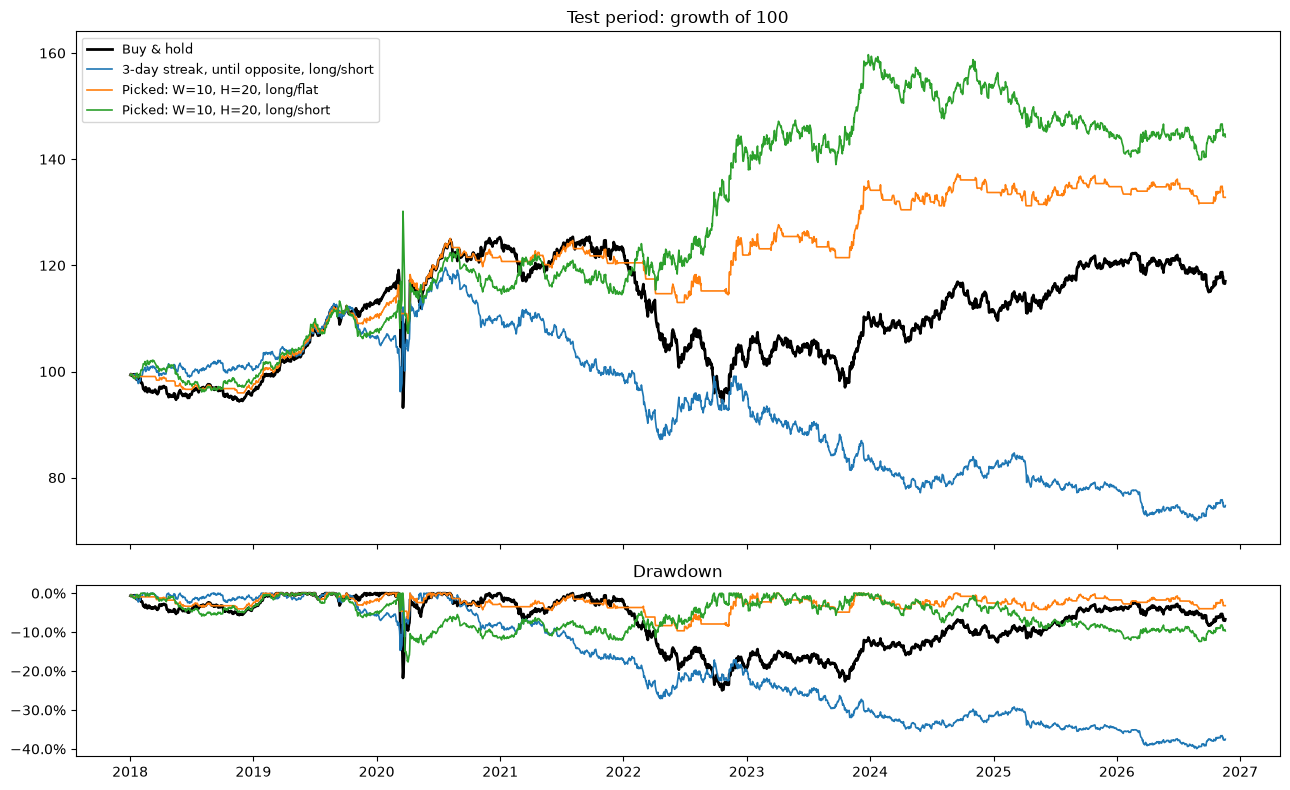

In [11]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
for label, bt in strategies.items():
    r = bt.loc[slice(*TEST), 'ret']
    equity = 100 * (1 + r).cumprod()
    style = {'color': 'black', 'lw': 2} if label == 'Buy & hold' else {'lw': 1.2}
    ax1.plot(equity, label=label, **style)
    ax2.plot(equity / equity.cummax().clip(lower=100) - 1, **style)
ax1.set_title('Test period: growth of 100')
ax1.legend(fontsize=9)
ax2.set_title('Drawdown')
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

## Conclusions

The picked rule (long on a new 10-day high, cash on a new 10-day low, hold 20 days) beat buy and hold after 2018: Sharpe 0.61 vs 0.24, CAGR 3.3% vs 1.8%, max drawdown −10% vs −25%. Most of the gain comes from sitting out sell-offs (2008-09, 2022). In calm years it lags slightly.

**Strengths:** simple, two parameters, works across nearby settings, holds up at 5 bp, much smaller drawdowns.

**Weaknesses:** lags at turning points; long/short only does well because of 2022; one asset and one split; cash earns 0%; no borrow fees.

**Possible improvements:** T-bill interest on cash, volatility-based sizing, testing on other bond ETFs, combining with the moving-average signal.